In [19]:
import gzip
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
    davies_bouldin_score,
    confusion_matrix
)

# 绘图字体与负号配置
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 全局超参数与随机种子配置
SEED = 42
SAMPLE_RATIO = 0.1     # 评估样本比例 (7000 个样本)
PCA_N_COMPONENTS = 50  # 前置实验确定的最优维数
PCA_WHITEN = False     # 前置实验确定的最优白化设置

In [20]:
DATA_DIR = Path('dataset')
DATA_DIR.mkdir(exist_ok=True)

BASE_URL = 'http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/'
FILES = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
         't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']

for fname in FILES:
    if not (DATA_DIR / fname).exists():
        print(f'下载 {fname} ...')
        urllib.request.urlretrieve(BASE_URL + fname, DATA_DIR / fname)

def load_images(path):
    with gzip.open(path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 784)

def load_labels(path):
    with gzip.open(path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=8)

X_full = np.concatenate([load_images(DATA_DIR / FILES[0]),
                         load_images(DATA_DIR / FILES[2])]).astype(np.float32) / 255.0
y_full = np.concatenate([load_labels(DATA_DIR / FILES[1]),
                         load_labels(DATA_DIR / FILES[3])])

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# 抽取分层采样评估样本集 X, y (与前置项目完全保持一致)
sample_idx, _ = train_test_split(
    np.arange(len(y_full)),
    train_size=SAMPLE_RATIO,
    stratify=y_full,
    random_state=SEED,
)
sample_idx = np.sort(sample_idx)

X = X_full[sample_idx]
y = y_full[sample_idx]

print(f"数据加载完成！评估样本集形状: X={X.shape}, y={y.shape}")
print(f"每类样本均衡数: {np.bincount(y).tolist()}")

数据加载完成！评估样本集形状: X=(7000, 784), y=(7000,)
每类样本均衡数: [700, 700, 700, 700, 700, 700, 700, 700, 700, 700]


In [21]:
# 1. 拟合并应用前置实验选定的最优 PCA 模型
pca = PCA(n_components=PCA_N_COMPONENTS, whiten=PCA_WHITEN, random_state=SEED)
X_pca = pca.fit_transform(X)

print(f"PCA 降维特征提取完成: {X.shape[1]} 维 -> {X_pca.shape[1]} 维")
print(f"前 {PCA_N_COMPONENTS} 个主成分累计解释方差 (EVR): {pca.explained_variance_ratio_.sum():.2%}")

# 2. 计算固定底图的 2D t-SNE 坐标（用于统一视角可视化）
print("正在生成 2D t-SNE 空间投影坐标（用于可视化）...")
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
X_tsne = tsne.fit_transform(X_pca)

eval_records = []
predictions = {}

np.random.seed(SEED)
sub_idx = np.random.choice(len(X_pca), size=min(len(X_pca), 3000), replace=False)

# 3. 封装统一的画图函数（增加颜色图例）
def evaluate_and_plot(name, preds):
    ari = adjusted_rand_score(y, preds)
    nmi = normalized_mutual_info_score(y, preds)
    score = (ari + nmi) / 2
    sil = silhouette_score(X_pca[sub_idx], preds[sub_idx])
    dbi = davies_bouldin_score(X_pca, preds)
    
    res = {
        '模型': name,
        '综合 score (↑)': score,
        'ARI (↑)': ari,
        'NMI (↑)': nmi,
        'Silhouette (↑)': sil,
        'DBI (↓)': dbi
    }
    eval_records.append(res)
    predictions[name] = preds
    
    # 打印单模型指标卡
    df_single = pd.DataFrame([res]).set_index('模型')
    display(df_single.style.format('{:.3f}').set_caption(f'【{name}】聚类评估指标'))
    
    # 双子图：左侧 t-SNE 散点图（带图例），右侧 混淆热力图
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    
    # 子图 1: t-SNE 散点图
    scatter = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=preds, cmap='tab10', s=8, alpha=0.75)
    axes[0].set_title(f"{name} 2D 聚类流形分布 (ARI: {ari:.3f})", fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    # 为散点图添加独立的颜色-簇标签图例
    handles, _ = scatter.legend_elements(prop="colors", alpha=0.8)
    cluster_labels = [f"Cluster {i}" for i in range(10)]
    axes[0].legend(handles, cluster_labels, title="聚类簇标识", loc="center left", 
                   bbox_to_anchor=(1.0, 0.5), frameon=True, fontsize=9, markerscale=1.5)
    
    # 子图 2: 真实品类混淆热力图
    cm = confusion_matrix(y, preds)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[1],
                xticklabels=[f'C{i}' for i in range(10)], yticklabels=CLASS_NAMES)
    axes[1].set_title(f"{name} 真实品类分配纯度映射", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("聚类簇编号 (Cluster ID)")
    axes[1].set_ylabel("真实品类 (Ground Truth)")
    
    plt.tight_layout()
    plt.show()

print("公用评估与可视化工具函数封装就绪。")

PCA 降维特征提取完成: 784 维 -> 50 维
前 50 个主成分累计解释方差 (EVR): 86.29%
正在生成 2D t-SNE 空间投影坐标（用于可视化）...
公用评估与可视化工具函数封装就绪。


,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
K-Means,0.428,0.337,0.519,0.206,1.600


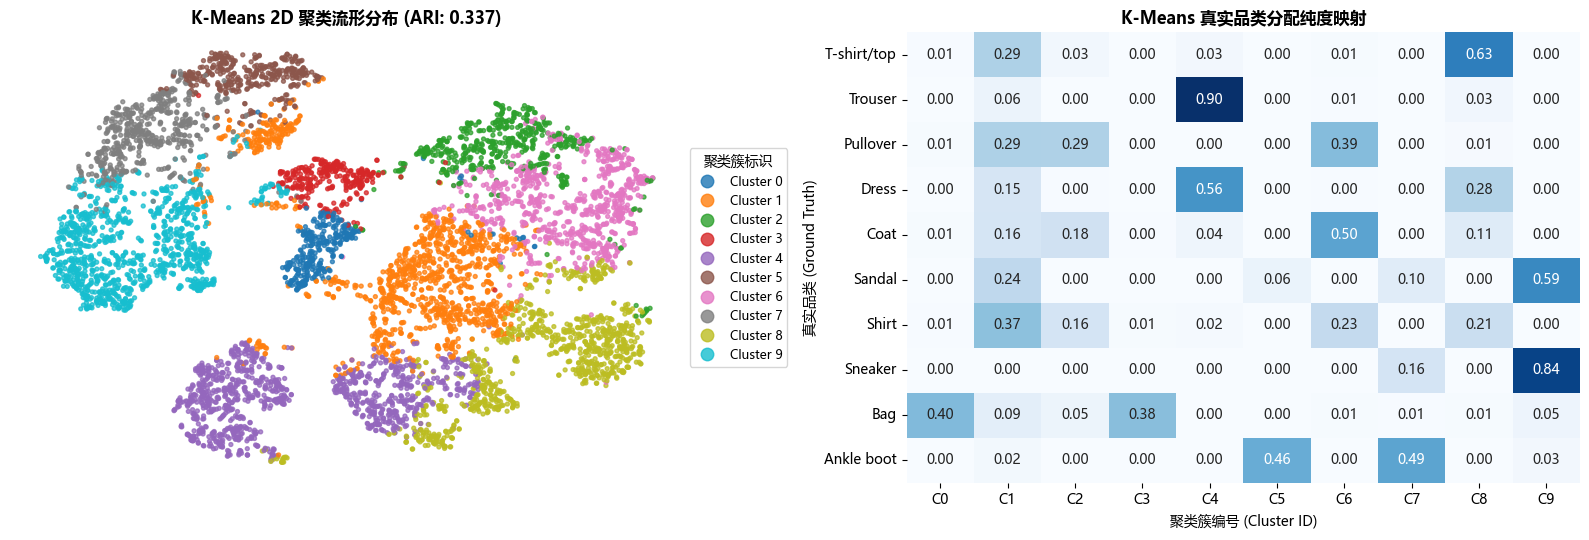

In [22]:
# 1. 初始化并训练 K-Means 模型
kmeans = KMeans(n_clusters=10, n_init=10, random_state=SEED)
preds_kmeans = kmeans.fit_predict(X_pca)

# 2. 评估并绘图
evaluate_and_plot('K-Means', preds_kmeans)

,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
GMM,0.417,0.318,0.515,0.102,2.201


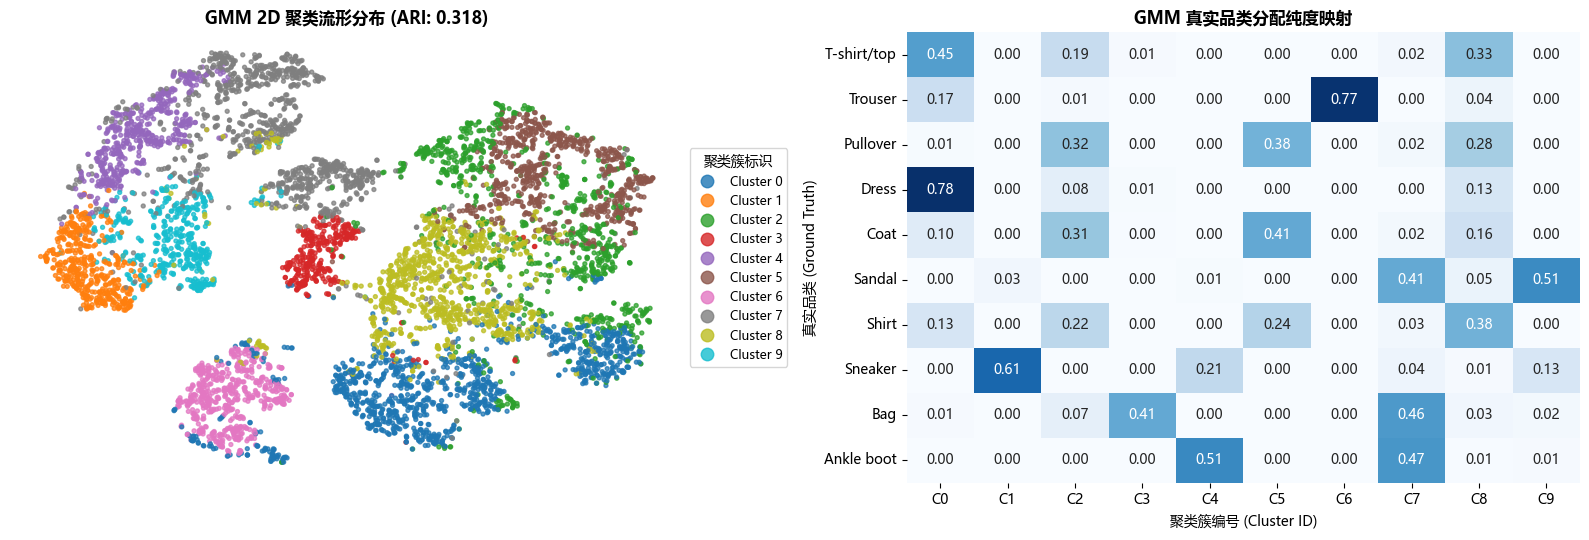

In [23]:
# 1. 初始化并训练 GMM 模型（选用 diag 对角协方差以适配正交主成分空间）
gmm = GaussianMixture(n_components=10, covariance_type='diag', random_state=SEED)
preds_gmm = gmm.fit_predict(X_pca)

# 2. 评估并绘图
evaluate_and_plot('GMM', preds_gmm)

,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
Agglomerative,0.473,0.379,0.567,0.179,1.602


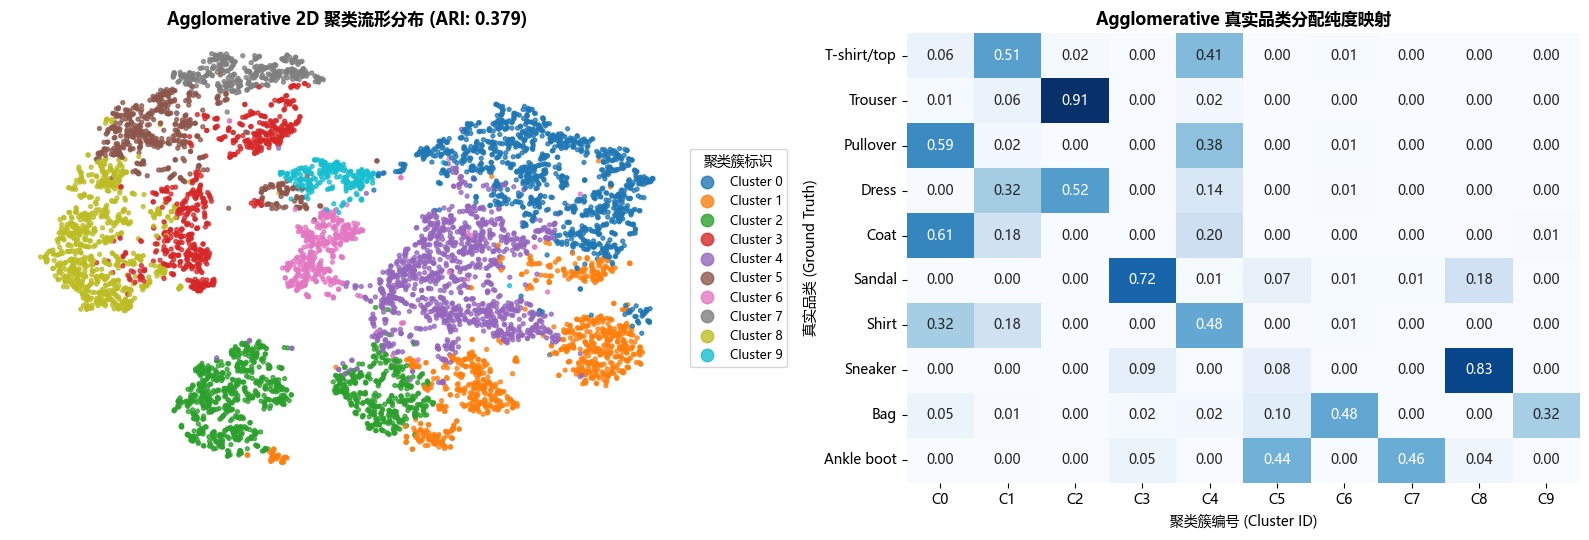

In [24]:
# 1. 初始化并训练层次凝聚聚类模型（选用 ward 最小方差准则）
agg = AgglomerativeClustering(n_clusters=10, linkage='ward')
preds_agg = agg.fit_predict(X_pca)

# 2. 评估并绘图
evaluate_and_plot('Agglomerative', preds_agg)

,综合 score (↑),ARI (↑),NMI (↑),Silhouette (↑),DBI (↓)
模型,,,,,
K-Means,0.428,0.337,0.519,0.206,1.600
GMM,0.417,0.318,0.515,0.102,2.201
Agglomerative,0.473,0.379,0.567,0.179,1.602


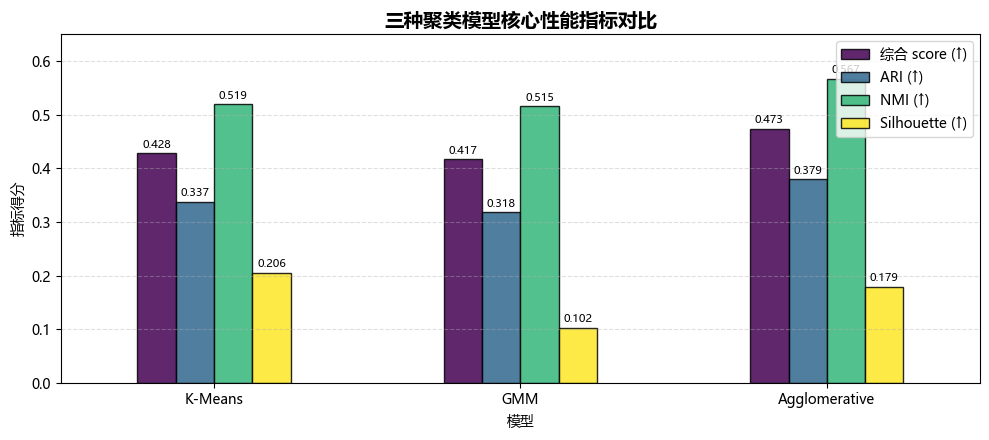

In [26]:
# 1. 汇总三种算法评估指标大表
df_summary = pd.DataFrame(eval_records).set_index('模型')

display(df_summary.style.format('{:.3f}')
        .background_gradient(cmap='Greens', subset=['综合 score (↑)', 'ARI (↑)', 'NMI (↑)', 'Silhouette (↑)'])
        .background_gradient(cmap='Reds_r', subset=['DBI (↓)'])
        .set_caption('表 1  三种聚类算法横向性能对比综合表'))

# 2. 绘制四大核心指标对比柱状图
fig, ax = plt.subplots(figsize=(10, 4.5))
metrics_plot = ['综合 score (↑)', 'ARI (↑)', 'NMI (↑)', 'Silhouette (↑)']
df_summary[metrics_plot].plot(kind='bar', ax=ax, rot=0, colormap='viridis', edgecolor='black', alpha=0.85)

ax.set_title("三种聚类模型核心性能指标对比", fontsize=14, fontweight='bold')
ax.set_ylabel("指标得分")
ax.set_ylim(0, 0.65)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(frameon=True, loc='upper right')

# 在柱状图上方标注具体数值
for p in ax.patches:
    val = p.get_height()
    if val > 0.01:
        ax.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()

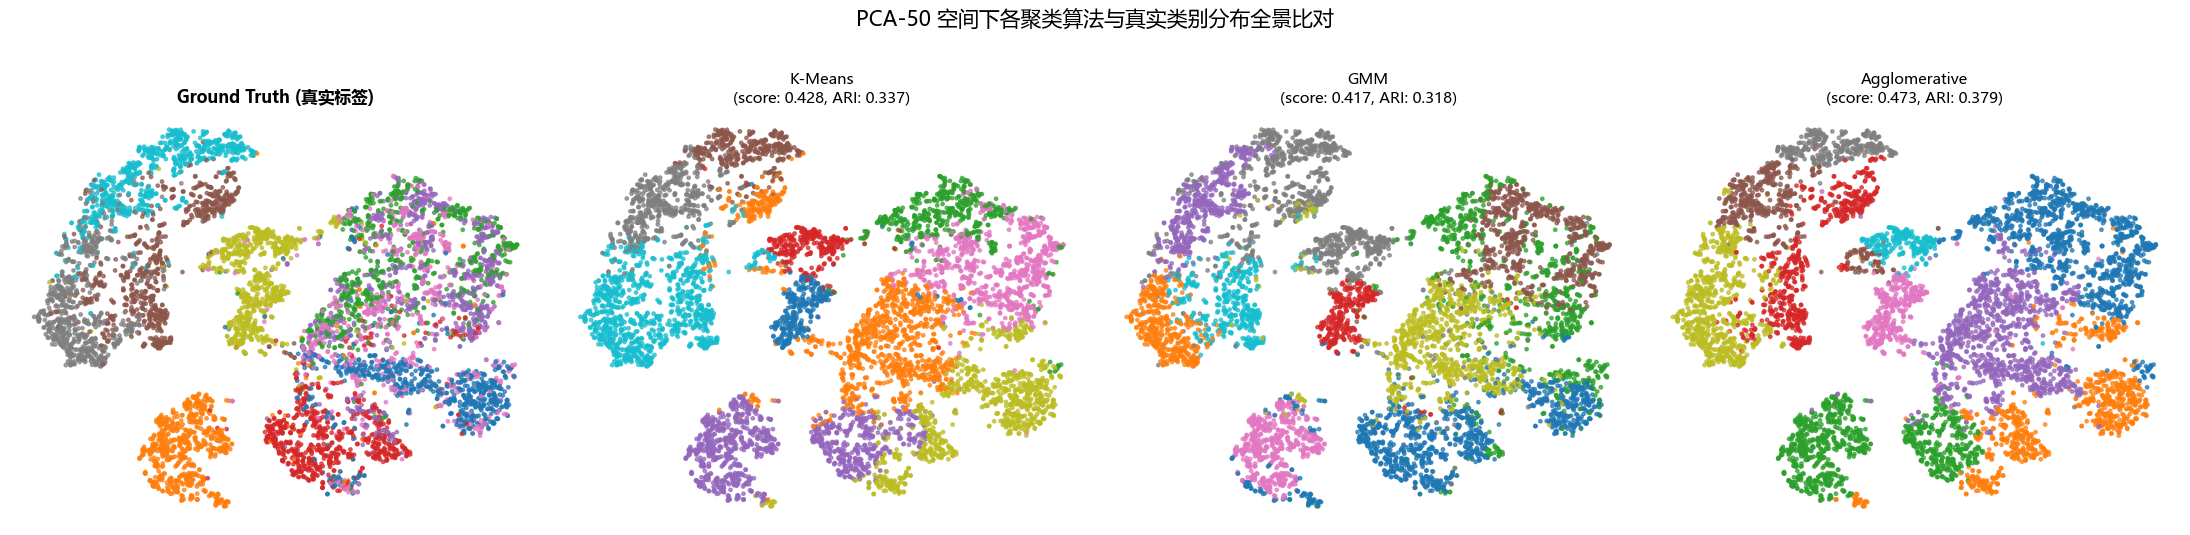

In [27]:
# 绘制 Ground Truth 与三种算法预测的并排流形散点图
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))

# 真实标签
axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='tab10', s=6, alpha=0.7)
axes[0].set_title("Ground Truth (真实标签)", fontsize=12, fontweight='bold')
axes[0].axis('off')

# 各模型聚类结果
for i, (name, preds) in enumerate(predictions.items(), start=1):
    axes[i].scatter(X_tsne[:, 0], X_tsne[:, 1], c=preds, cmap='tab10', s=6, alpha=0.7)
    score_val = df_summary.loc[name, '综合 score (↑)']
    ari_val = df_summary.loc[name, 'ARI (↑)']
    axes[i].set_title(f"{name}\n(score: {score_val:.3f}, ARI: {ari_val:.3f})", fontsize=11)
    axes[i].axis('off')

plt.suptitle("PCA-50 空间下各聚类算法与真实类别分布全景比对", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()